<a href="https://colab.research.google.com/github/FrancoPanico/point-gesture-recognition-model/blob/main/keypoints_jointpoints_preprocessing_beta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

ROOT_PATH = '/content/drive'
drive.mount(ROOT_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder_path = Path('/content/drive/MyDrive/Neuroengeneering_PW2/Data')

# Dictionary to collect structured data without mixing different videos
# Structure: { 'Participant_Name': { 'Video_1': { 'jointpoints': Path, ... }, 'Video_2': {...} } }
experiment_data = {}

if folder_path.exists():
    print(f"Analyzing main folder: {folder_path}\n")

    # 1. Iterate over Participants
    for participant_dir in folder_path.iterdir():
        if participant_dir.is_dir():
            participant_name = participant_dir.name
            print(f"Participant found: {participant_name}")
            experiment_data[participant_name] = {}

            # 2. Iterate over Video subfolders
            for video_dir in participant_dir.iterdir():
                if video_dir.is_dir():
                    video_name = video_dir.name
                    print(f"  -> Video folder found: {video_name}")

                    experiment_data[participant_name][video_name] = {}

                    # Get all files in the video directory
                    all_files = [f for f in video_dir.iterdir() if f.is_file()]

                    # Key categories we are looking for
                    categories = {
                        'jointpoints': 'jointpoint',
                        'keypoints': 'keypoint',
                        'special_times': 'special_time',
                        'tempos': 'tempo',
                        'visual_analysis': 'visual_analysis'
                    }

                    for key, substring in categories.items():
                        # Case-insensitive substring match to find the file
                        matched_files = [f for f in all_files if substring in f.name.lower()]

                        if matched_files:
                            experiment_data[participant_name][video_name][key] = matched_files[0]
                            print(f"     - {key}: {matched_files[0].name}")
                        else:
                            experiment_data[participant_name][video_name][key] = None
                            print(f"     - {key}: NOT FOUND")
else:
    print(f"The path {folder_path} does not exist. Please check your Google Drive directory.")

Analyzing main folder: /content/drive/MyDrive/Neuroengeneering_PW2/Data

Participant found: Francesco
  -> Video folder found: 2
     - jointpoints: jointpoints1794231587.487558.txt
     - keypoints: keypoints1794231587.487558.txt
     - special_times: special_times1794231587.487558.txt
     - tempos: tempos1794231587.487558.txt
     - visual_analysis: visual_analysis.txt
  -> Video folder found: 1
     - jointpoints: jointpoints1794231363.979202.txt
     - keypoints: keypoints1794231363.979202.txt
     - special_times: special_times1794231363.979202.txt
     - tempos: tempos1794231363.979202.txt
     - visual_analysis: visual_analysis.txt
  -> Video folder found: 3
     - jointpoints: jointpoints1794231712.0208464.txt
     - keypoints: keypoints1794231712.0208464.txt
     - special_times: special_times1794231712.0208464.txt
     - tempos: tempos1794231712.0208464.txt
     - visual_analysis: visual_analysis.txt
Participant found: Martina
  -> Video folder found: 1
     - jointpoints: j

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# List to store final tabular results for all participants and videos
results_list = []

# Helper function to parse and validate the visual_analysis file
def parse_and_validate_visual_analysis(file_path):
    if not file_path or not Path(file_path).exists():
        return None

    gestures = []
    current_gesture = {}
    errors = []

    expected_next = 'start'

    with open(file_path, 'r') as f:
        for line_idx, line in enumerate(f, 1):
            parts = line.strip().split()
            if len(parts) < 2:
                continue
            try:
                timestamp = float(parts[0])
                label = parts[1].lower()
            except ValueError:
                continue

            # Validate label sequences
            if label == 'start':
                if expected_next != 'start':
                    errors.append(f"Line {line_idx}: Found 'start' but expected '{expected_next}' (Previous gesture was left incomplete at timestamp {timestamp})")
                current_gesture = {'start': timestamp}
                expected_next = 'pointing'

            elif label == 'pointing':
                if expected_next != 'pointing':
                    errors.append(f"Line {line_idx}: Found 'pointing' without a valid preceding 'start' at timestamp {timestamp}")
                    current_gesture = {}
                    expected_next = 'start'
                else:
                    current_gesture['pointing'] = timestamp
                    expected_next = 'end'

            elif label == 'end':
                if expected_next != 'end':
                    errors.append(f"Line {line_idx}: Found 'end' without a valid preceding 'pointing' at timestamp {timestamp}")
                    current_gesture = {}
                    expected_next = 'start'
                else:
                    current_gesture['end'] = timestamp
                    # Complete valid gesture found
                    gestures.append(current_gesture.copy())
                    current_gesture = {}
                    expected_next = 'start'

    # Handle case where file ends with an incomplete gesture
    if current_gesture:
        errors.append(f"End of file: Incomplete gesture left open: {current_gesture}")

    # Print validation errors if any were found
    if errors:
        print(f"\n[!] LABELING ERRORS DETECTED in {Path(file_path).name}:")
        for err in errors:
            print(f"  - {err}")
    else:
        print(f"  -> {Path(file_path).name}: Label sequence is 100% valid.")

    return gestures

# Process all participants and videos stored in experiment_data
for participant, videos in experiment_data.items():
    print(f"\nAnalyzing participant: {participant}")
    for video_name, files in videos.items():
        visual_analysis_file = files.get('visual_analysis')

        if visual_analysis_file:
            gestures = parse_and_validate_visual_analysis(visual_analysis_file)

            if gestures:
                durations = []
                time_to_pointings = []
                pointing_to_ends = []

                for g in gestures:
                    durations.append(g['end'] - g['start'])
                    time_to_pointings.append(g['pointing'] - g['start'])
                    pointing_to_ends.append(g['end'] - g['pointing'])

                # Calculate means for this video
                results_list.append({
                    'Participant': participant,
                    'Video': video_name,
                    'Gesture Count': len(gestures),
                    'Mean Gesture Duration (s)': np.mean(durations),
                    'Mean Time to Pointing (s)': np.mean(time_to_pointings),
                    'Mean Pointing-to-End (s)': np.mean(pointing_to_ends)
                })
            else:
                print(f"Warning: No valid gesture data found in {visual_analysis_file.name}")
        else:
            print(f"Warning: visual_analysis file missing for {participant} - {video_name}")

# Convert results to a pandas DataFrame for output presentation
if results_list:
    df_results = pd.DataFrame(results_list)
    display(df_results)
else:
    print("No data was processed. Please make sure experiment_data contains valid paths.")


Analyzing participant: Francesco
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.

Analyzing participant: Martina
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.

Analyzing participant: Amirhossein
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.

Analyzing participant: Shaghayegh
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.

Analyzing participant: Sara
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% valid.
  -> visual_analysis.txt: Label sequence is 100% v

,Participant,Video,Gesture Count,Mean Gesture Duration (s),Mean Time to Pointing (s),Mean Pointing-to-End (s)
0,Francesco,2,18,1.761501,0.702704,1.058797
1,Francesco,1,18,2.014730,0.725826,1.288903
2,Francesco,3,42,1.671532,0.613458,1.058074
3,Martina,1,18,3.047997,1.108926,1.939071
4,Martina,3,42,2.515436,0.813216,1.702220
5,Martina,2,18,2.991628,0.961523,2.030106
6,Amirhossein,1,18,2.027553,0.661905,1.365647
7,Amirhossein,2,17,1.949041,0.654582,1.294459
8,Amirhossein,3,42,1.726757,0.806590,0.920168
9,Shaghayegh,sh 1,21,2.333761,0.751030,1.582731


In [ ]:
# Calculate the global mean of all video trials for all participants
# Grouping by participant to see their overall average performance across videos
overall_participant_means = df_results.groupby('Participant')[[
    'Mean Gesture Duration (s)',
    'Mean Time to Pointing (s)',
    'Mean Pointing-to-End (s)'
]].mean().reset_index()

print("=== Overall Means per Participant (Across All Videos) ===")
display(overall_participant_means)

# Also calculate the grand average across the entire experiment
grand_means = df_results[[
    'Mean Gesture Duration (s)',
    'Mean Time to Pointing (s)',
    'Mean Pointing-to-End (s)'
]].mean().to_frame(name='Grand Average (All Videos & Participants)').T

print("\n=== Grand Average (All Video Trials combined) ===")
display(grand_means)

=== Overall Means per Participant (Across All Videos) ===


,Participant,Mean Gesture Duration (s),Mean Time to Pointing (s),Mean Pointing-to-End (s)
0,Amirhossein,1.901117,0.707692,1.193425
1,Francesco,1.815921,0.680663,1.135258
2,Martina,2.851687,0.961222,1.890466
3,Sara,1.266854,0.641935,0.624919
4,Shaghayegh,1.910233,0.700908,1.209325



=== Grand Average (All Video Trials combined) ===


,Mean Gesture Duration (s),Mean Time to Pointing (s),Mean Pointing-to-End (s)
Grand Average (All Videos & Participants),1.949163,0.738484,1.210678


In [ ]:
import os
import numpy as np
from scipy.interpolate import PchipInterpolator
from scipy.signal import butter, filtfilt

# Indici standard Azure Kinect (32 joint)
PELVIS_IDX = 0
NECK_IDX = 3


def parse_raw_keypoints_3d(filepath, target_subject_id=0):
  """Legge il file keypoints (98 colonne: id, timestamp, 32*3 coords XYZ).

  Scarta righe corrotte/troncate e restituisce timestamps (N,) e coords (N, 32,
  2).
  """
  timestamps = []
  coords_xy = []

  with open(filepath, "r", encoding="utf-8") as f:
    for line in f:
      parts = line.strip().split()
      # Verifica integrità riga (1 id + 1 timestamp + 96 coordinate = 98)
      if len(parts) != 98:
        continue
      try:
        subj_id = int(float(parts[0]))
        if subj_id != target_subject_id:
          continue
        ts = float(parts[1])
        raw_vals = np.array([float(x) for x in parts[2:]], dtype=np.float64)
        joints_3d = raw_vals.reshape(32, 3)

        # Estrazione delle sole coordinate X, Y
        timestamps.append(ts)
        coords_xy.append(joints_3d[:, :2])
      except ValueError:
        continue

  if len(timestamps) < 5:
    return None, None

  timestamps = np.array(timestamps, dtype=np.float64)
  coords_xy = np.array(coords_xy, dtype=np.float64)

  # Rimozione eventuali timestamp duplicati o non strettamente crescenti
  _, unique_idx = np.unique(timestamps, return_index=True)
  timestamps = timestamps[unique_idx]
  coords_xy = coords_xy[unique_idx]

  return timestamps, coords_xy


def preprocess_keypoints_file(
    filepath, target_fps=15.0, cutoff_hz=4.0, filter_order=4
):
  """Esegue l'intera pipeline di preprocessing sui keypoints.

  Restituisce il dizionario strutturato richiesto.
  """
  timestamps, coords = parse_raw_keypoints_3d(filepath)
  if timestamps is None:
    return None

  # 1. Gestione occlusioni (valori NaN o coordinate nulle [0, 0]) tramite PCHIP
  # Se un joint ha sia X=0 che Y=0 contemporaneamente, lo trattiamo come occluso
  occluded_mask = (coords[:, :, 0] == 0.0) & (coords[:, :, 1] == 0.0)
  coords[occluded_mask] = np.nan

  for j in range(32):
    for d in range(2):
      series = coords[:, j, d]
      valid = ~np.isnan(series)
      if np.sum(valid) >= 2:
        interp_func = PchipInterpolator(
            timestamps[valid], series[valid], extrapolate=True
        )
        coords[:, j, d] = interp_func(timestamps)
      else:
        # Fallback se il joint è completamente assente
        coords[:, j, d] = 0.0

  # 2. Ricampionamento su griglia temporale uniforme a 15.0 Hz
  t_start, t_end = timestamps[0], timestamps[-1]
  dt = 1.0 / target_fps
  uniform_timestamps = np.arange(t_start, t_end, dt)

  if len(uniform_timestamps) < 15:  # Troppo corto per filtraggio filtfilt
    return None

  resampled_coords = np.zeros(
      (len(uniform_timestamps), 32, 2), dtype=np.float64
  )
  for j in range(32):
    for d in range(2):
      pchip = PchipInterpolator(timestamps, coords[:, j, d])
      resampled_coords[:, j, d] = pchip(uniform_timestamps)

  # 3. Filtro Butterworth passa-basso a 4 Hz (zero-phase con filtfilt)
  nyquist = 0.5 * target_fps
  normal_cutoff = cutoff_hz / nyquist
  b, a = butter(filter_order, normal_cutoff, btype="low", analog=False)

  filtered_coords = np.zeros_like(resampled_coords)
  for j in range(32):
    for d in range(2):
      filtered_coords[:, j, d] = filtfilt(b, a, resampled_coords[:, j, d])

  # 4. Normalizzazione spaziale (centratura su Pelvis e scaling Pelvis-Neck)
  pelvis_pos = filtered_coords[:, PELVIS_IDX : PELVIS_IDX + 1, :]  # (Frames, 1, 2)
  centered_coords = filtered_coords - pelvis_pos

  # Calcolo distanza anatomica media Pelvis - Neck su tutto il video
  neck_rel = centered_coords[:, NECK_IDX, :]  # (Frames, 2)
  torso_lengths = np.linalg.norm(neck_rel, axis=1)
  scale_factor = float(np.median(torso_lengths))  # Mediana robusta agli outlier

  if scale_factor <= 1e-6:
    scale_factor = 1.0

  normalized_positions = centered_coords / scale_factor

  # 5. Calcolo Velocità e Accelerazione tramite derivate numeriche su griglia uniforme (dt)
  velocity = np.gradient(normalized_positions, dt, axis=0)
  acceleration = np.gradient(velocity, dt, axis=0)

  return {
      "positions": normalized_positions.astype(np.float32),
      "velocity": velocity.astype(np.float32),
      "acceleration": acceleration.astype(np.float32),
      "timestamps": uniform_timestamps,
      "scale_factor": scale_factor,
  }

Detailed Breakdown of functions
1. preprocess_keypoint_sequence
This is the core function that processes a single raw text file containing the tracking coordinate sequence over time. It performs 6 main sequential operations:

Step 1: Robust Parsing & Malformed Row Filtering

Reads the file line by line and counts the columns in each row to detect the expected pattern (identifying if there are extra metadata fields like a subject ID).
Filters out corrupt or incomplete rows that do not match the dominant column count (expected_cols), converting valid lines into a structured NumPy float64 array.
Reshapes the flattened coordinate columns into a 3D tensor of shape (Frames, Joints, 2D/3D Coordinates).
Sorts frames chronologically and drops exact duplicate timestamps.
Step 2: Occlusion / Outlier Masking & PCHIP Interpolation

Occlusion Handling: Values very close to $(0,0)$$(0,0)$ are treated as sensor tracking failures and masked with NaN.
Outlier Removal: Applies a 5-frame rolling median filter to calculate expected local positions. Any coordinate jumping more than $100$$100$ units from this median is flagged as a tracking glitch and masked.
PCHIP Interpolation: Replaces NaN gaps using PCHIP (Piecewise Cubic Hermite Interpolating Polynomial). This method is crucial for motion because it preserves monotonicity and prevents the artificial 'overshooting' or oscillations common with standard cubic splines.
Step 3: Temporal Resampling to a Uniform Grid

Raw sensor frames are rarely spaced perfectly over time. This step establishes a uniform temporal grid with a constant target frame rate (e.g., $15.0$$15.0$ FPS).
Linear interpolation (interp1d) aligns the coordinates onto this new grid, solving time jitter and micro-lag issues.
Step 4: Zero-Phase Butterworth Low-Pass Filtering

Applies a 4th-order low-pass Butterworth filter with a specified cutoff frequency (e.g., $4.0$$4.0$ Hz) to eliminate high-frequency hand tremors and depth sensor jitter.
Uses filtfilt (zero-phase filtering) which processes the signal forwards and backwards. This is critical because it filters the noise without shifting the temporal position of events (zero phase delay).
Step 5: Spatial Normalization (Translation & Scale Invariance)

Translation Invariance: Centers the coordinates by subtracting a chosen reference root joint (usually the Pelvis, index 0) from all other joint coordinates in each frame. This makes the data independent of where the person stands in the room.
Scale Invariance: Computes the Euclidean distance between two reliable joints (e.g., Pelvis to Neck) over time. It scales all coordinate coordinates by the median of this distance, adjusting for different body heights or camera perspective scaling (shrinking/growing artifacts).
Step 6: Kinematic Derivatives

Calculates the first derivative (Velocity) and second derivative (Acceleration) of the normalized coordinates relative to the uniform time step $dt$$dt$ using np.gradient.
2. process_dataset_dictionary
This wrapper function automates the pipeline over your entire nested project data dictionary:

It iterates through every participant and recorded video trial inside experiment_data.
It automatically searches for the correct tracking modality file (checking for keypoints first, falling back to jointpoints).
It feeds the active file to preprocess_keypoint_sequence under standard parameters ($15$$15$ FPS target, $4$$4$ Hz cutoff, pelvis normalization).
It packages the outputs (timestamps, normalized positions, velocities, accelerations) and stores them back into a structured dictionary, ready for window segmentation and training.

In [ ]:
import os
import numpy as np
from scipy.interpolate import PchipInterpolator
from scipy.signal import butter, filtfilt

# Indici standard Azure Kinect (32 joint)
PELVIS_IDX = 0
NECK_IDX = 3


def parse_raw_keypoints_3d(filepath, target_subject_id=0):
  """Legge il file keypoints (98 colonne: id, timestamp, 32*3 coords XYZ).

  Scarta righe corrotte/troncate e restituisce timestamps (N,) e coords (N, 32,
  2).
  """
  timestamps = []
  coords_xy = []

  with open(filepath, "r", encoding="utf-8") as f:
    for line in f:
      parts = line.strip().split()
      # Verifica integrità riga (1 id + 1 timestamp + 96 coordinate = 98)
      if len(parts) != 98:
        continue
      try:
        subj_id = int(float(parts[0]))
        if subj_id != target_subject_id:
          continue
        ts = float(parts[1])
        raw_vals = np.array([float(x) for x in parts[2:]], dtype=np.float64)
        joints_3d = raw_vals.reshape(32, 3)

        # Estrazione delle sole coordinate X, Y
        timestamps.append(ts)
        coords_xy.append(joints_3d[:, :2])
      except ValueError:
        continue

  if len(timestamps) < 5:
    return None, None

  timestamps = np.array(timestamps, dtype=np.float64)
  coords_xy = np.array(coords_xy, dtype=np.float64)

  # Rimozione eventuali timestamp duplicati o non strettamente crescenti
  _, unique_idx = np.unique(timestamps, return_index=True)
  timestamps = timestamps[unique_idx]
  coords_xy = coords_xy[unique_idx]

  return timestamps, coords_xy


def preprocess_keypoints_file(
    filepath, target_fps=15.0, cutoff_hz=4.0, filter_order=4
):
  """Esegue l'intera pipeline di preprocessing sui keypoints.

  Restituisce il dizionario strutturato richiesto.
  """
  timestamps, coords = parse_raw_keypoints_3d(filepath)
  if timestamps is None:
    return None

  # 1. Gestione occlusioni (valori NaN o coordinate nulle [0, 0]) tramite PCHIP
  # Se un joint ha sia X=0 che Y=0 contemporaneamente, lo trattiamo come occluso
  occluded_mask = (coords[:, :, 0] == 0.0) & (coords[:, :, 1] == 0.0)
  coords[occluded_mask] = np.nan

  for j in range(32):
    for d in range(2):
      series = coords[:, j, d]
      valid = ~np.isnan(series)
      if np.sum(valid) >= 2:
        interp_func = PchipInterpolator(
            timestamps[valid], series[valid], extrapolate=True
        )
        coords[:, j, d] = interp_func(timestamps)
      else:
        # Fallback se il joint è completamente assente
        coords[:, j, d] = 0.0

  # 2. Ricampionamento su griglia temporale uniforme a 15.0 Hz
  t_start, t_end = timestamps[0], timestamps[-1]
  dt = 1.0 / target_fps
  uniform_timestamps = np.arange(t_start, t_end, dt)

  if len(uniform_timestamps) < 15:  # Troppo corto per filtraggio filtfilt
    return None

  resampled_coords = np.zeros(
      (len(uniform_timestamps), 32, 2), dtype=np.float64
  )
  for j in range(32):
    for d in range(2):
      pchip = PchipInterpolator(timestamps, coords[:, j, d])
      resampled_coords[:, j, d] = pchip(uniform_timestamps)

  # 3. Filtro Butterworth passa-basso a 4 Hz (zero-phase con filtfilt)
  nyquist = 0.5 * target_fps
  normal_cutoff = cutoff_hz / nyquist
  b, a = butter(filter_order, normal_cutoff, btype="low", analog=False)

  filtered_coords = np.zeros_like(resampled_coords)
  for j in range(32):
    for d in range(2):
      filtered_coords[:, j, d] = filtfilt(b, a, resampled_coords[:, j, d])

  # 4. Normalizzazione spaziale (centratura su Pelvis e scaling Pelvis-Neck)
  pelvis_pos = filtered_coords[:, PELVIS_IDX : PELVIS_IDX + 1, :]  # (Frames, 1, 2)
  centered_coords = filtered_coords - pelvis_pos

  # Calcolo distanza anatomica media Pelvis - Neck su tutto il video
  neck_rel = centered_coords[:, NECK_IDX, :]  # (Frames, 2)
  torso_lengths = np.linalg.norm(neck_rel, axis=1)
  scale_factor = float(np.median(torso_lengths))  # Mediana robusta agli outlier

  if scale_factor <= 1e-6:
    scale_factor = 1.0

  normalized_positions = centered_coords / scale_factor

  # 5. Calcolo Velocità e Accelerazione tramite derivate numeriche su griglia uniforme (dt)
  velocity = np.gradient(normalized_positions, dt, axis=0)
  acceleration = np.gradient(velocity, dt, axis=0)

  return {
      "positions": normalized_positions.astype(np.float32),
      "velocity": velocity.astype(np.float32),
      "acceleration": acceleration.astype(np.float32),
      "timestamps": uniform_timestamps,
      "scale_factor": scale_factor,
  }

In [ ]:
import os
import numpy as np
from scipy.interpolate import PchipInterpolator
from scipy.signal import butter, filtfilt

PELVIS_IDX = 0
NECK_IDX = 3


def parse_raw_jointpoints_2d(filepath, target_subject_id=0):
  """Legge il file jointpoints (66 colonne: id, timestamp, 32*2 coords XY).

  Gestisce anche l'eventuale formato a 98 colonne prendendo le prime 2
  coordinate per joint.
  """
  timestamps = []
  coords_xy = []

  with open(filepath, "r", encoding="utf-8") as f:
    for line in f:
      parts = line.strip().split()
      n_cols = len(parts)
      if n_cols not in (66, 98):
        continue
      try:
        subj_id = int(float(parts[0]))
        if subj_id != target_subject_id:
          continue
        ts = float(parts[1])
        raw_vals = np.array([float(x) for x in parts[2:]], dtype=np.float64)

        if n_cols == 66:
          joints_xy = raw_vals.reshape(32, 2)
        else:
          joints_xy = raw_vals.reshape(32, 3)[:, :2]

        timestamps.append(ts)
        coords_xy.append(joints_xy)
      except ValueError:
        continue

  if len(timestamps) < 5:
    return None, None

  timestamps = np.array(timestamps, dtype=np.float64)
  coords_xy = np.array(coords_xy, dtype=np.float64)

  _, unique_idx = np.unique(timestamps, return_index=True)
  timestamps = timestamps[unique_idx]
  coords_xy = coords_xy[unique_idx]

  return timestamps, coords_xy


def preprocess_jointpoints_file(
    filepath, target_fps=15.0, cutoff_hz=4.0, filter_order=4
):
  """Esegue l'intera pipeline di preprocessing sui jointpoints 2D."""
  timestamps, coords = parse_raw_jointpoints_2d(filepath)
  if timestamps is None:
    return None

  # 1. Gestione occlusioni: nei jointpoints 2D i punti fuori frame o occlusi
  # possono assumere valori (0, 0) o coordinate negative
  occluded_mask = (
      ((coords[:, :, 0] == 0.0) & (coords[:, :, 1] == 0.0))
      | (coords[:, :, 0] < 0.0)
      | (coords[:, :, 1] < 0.0)
  )
  coords[occluded_mask] = np.nan

  for j in range(32):
    for d in range(2):
      series = coords[:, j, d]
      valid = ~np.isnan(series)
      if np.sum(valid) >= 2:
        interp_func = PchipInterpolator(
            timestamps[valid], series[valid], extrapolate=True
        )
        coords[:, j, d] = interp_func(timestamps)
      else:
        coords[:, j, d] = 0.0

  # 2. Ricampionamento uniforme a 15.0 Hz
  t_start, t_end = timestamps[0], timestamps[-1]
  dt = 1.0 / target_fps
  uniform_timestamps = np.arange(t_start, t_end, dt)

  if len(uniform_timestamps) < 15:
    return None

  resampled_coords = np.zeros(
      (len(uniform_timestamps), 32, 2), dtype=np.float64
  )
  for j in range(32):
    for d in range(2):
      pchip = PchipInterpolator(timestamps, coords[:, j, d])
      resampled_coords[:, j, d] = pchip(uniform_timestamps)

  # 3. Filtro Butterworth passa-basso a 4 Hz
  nyquist = 0.5 * target_fps
  normal_cutoff = cutoff_hz / nyquist
  b, a = butter(filter_order, normal_cutoff, btype="low", analog=False)

  filtered_coords = np.zeros_like(resampled_coords)
  for j in range(32):
    for d in range(2):
      filtered_coords[:, j, d] = filtfilt(b, a, resampled_coords[:, j, d])

  # 4. Normalizzazione spaziale (centratura su Pelvis e scaling Pelvis-Neck)
  # Nota: in coordinate immagine Y punta verso il basso; la centratura e lo scaling
  # mantengono intatta la geometria relativa per le feature cinematiche.
  pelvis_pos = filtered_coords[:, PELVIS_IDX : PELVIS_IDX + 1, :]
  centered_coords = filtered_coords - pelvis_pos

  neck_rel = centered_coords[:, NECK_IDX, :]
  torso_lengths = np.linalg.norm(neck_rel, axis=1)
  scale_factor = float(np.median(torso_lengths))

  if scale_factor <= 1e-6:
    scale_factor = 1.0

  normalized_positions = centered_coords / scale_factor

  # 5. Derivazione numerica per velocità e accelerazione
  velocity = np.gradient(normalized_positions, dt, axis=0)
  acceleration = np.gradient(velocity, dt, axis=0)

  return {
      "positions": normalized_positions.astype(np.float32),
      "velocity": velocity.astype(np.float32),
      "acceleration": acceleration.astype(np.float32),
      "timestamps": uniform_timestamps,
      "scale_factor": scale_factor,
  }

In [ ]:
def build_processed_dataset(experiment_data):
  processed_experiment_data = {}

  for participant, videos in experiment_data.items():
    processed_experiment_data[participant] = {}

    for video_id, files in videos.items():
      kp_path = files.get("keypoints")
      jp_path = files.get("jointpoints")

      video_dict = {}

      if kp_path is not None and os.path.exists(kp_path):
        res_kp = preprocess_keypoints_file(kp_path)
        if res_kp is not None:
          video_dict["preprocessed_keypoints"] = res_kp

      if jp_path is not None and os.path.exists(jp_path):
        res_jp = preprocess_jointpoints_file(jp_path)
        if res_jp is not None:
          video_dict["preprocessed_jointpoints"] = res_jp

      # Salva la sessione solo se contiene almeno un flusso valido
      if video_dict:
        processed_experiment_data[participant][video_id] = video_dict

  return processed_experiment_data

In [ ]:
# 1. Eseguiamo il preprocessing completo su tutto il dataset
processed_experiment_data = build_processed_dataset(experiment_data)

# 2. Verifichiamo quanti partecipanti e video sono stati elaborati
total_sessions = 0
print("=== STATO DEL PREPROCESSING ===\n")
for participant, videos in processed_experiment_data.items():
    print(f"Partecipante: {participant}")
    for video_id, data in videos.items():
        modalities = list(data.keys())
        print(f"  -> Video {video_id} elaborato con successo! Modalità presenti: {modalities}")
        total_sessions += 1

print(f"\nTotale sessioni preprocessate con successo: {total_sessions}")

# 3. Test diagnostico di integrità dimensionale su una sessione d'esempio
print("\n=== TEST DIAGNOSTICO DI INTEGRITÀ (Esempio: Francesco - Video 1) ===")
if "Francesco" in processed_experiment_data and "1" in processed_experiment_data["Francesco"]:
    example_session = processed_experiment_data["Francesco"]["1"]
    # Scegliamo una modalità disponibile per il test (preferendo keypoints)
    active_key = "preprocessed_keypoints" if "preprocessed_keypoints" in example_session else "preprocessed_jointpoints"
    example_data = example_session[active_key]

    print(f"Modalità testata: {active_key}")
    print(f"- Dimensioni Posizioni (Frames, Joint, Coordinate XY) : {example_data['positions'].shape} (Atteso: (N, 32, 2))")
    print(f"- Dimensioni Velocità (Frames, Joint, Coordinate XY)  : {example_data['velocity'].shape} (Atteso: (N, 32, 2))")
    print(f"- Dimensioni Accelerazione (Frames, Joint, Coordinate XY): {example_data['acceleration'].shape} (Atteso: (N, 32, 2))")
    print(f"- Range Timestamps (Uniformi a 15 Hz)                : {example_data['timestamps'][0]:.2f}s a {example_data['timestamps'][-1]:.2f}s")
    print(f"- Fattore di scala anatomico (Pelvis-Neck)            : {example_data['scale_factor']:.2f} mm/pixel")

    # Verifica assenza di valori nulli o NaN residui
    has_nans = np.isnan(example_data['positions']).any()
    print(f"- Presenza di valori NaN residui nelle posizioni     : {has_nans} (Atteso: False)")
else:
    print("Nessun dato di Francesco - Video 1 trovato per il test.")

=== STATO DEL PREPROCESSING ===

Partecipante: Francesco
  -> Video 2 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
  -> Video 1 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
  -> Video 3 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
Partecipante: Martina
  -> Video 1 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
  -> Video 3 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
  -> Video 2 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
Partecipante: Amirhossein
  -> Video 1 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
  -> Video 2 elaborato con successo! Modalità presenti: ['preprocessed_keypoints', 'preprocessed_jointpoints']
  -> Vi

=== CONFRONTO METRICHE DI QUALITÀ ===
Frequenza di campionamento:
  - Grezza: Variabile (Media dt: 95.9ms)
  - Preprocessata: Uniforme a 15 Hz (dt costante: 66.7ms)

Rumore di tracciamento (Mediana Accelerazione sul Right Wrist (Joint 14)):
  - Grezzo: 9.92 mm/frame²
  - Preprocessato (Normalizzato): 0.01367 unità/frame²
  -> Riduzione drastica del jitter e dei movimenti teletrasportati!


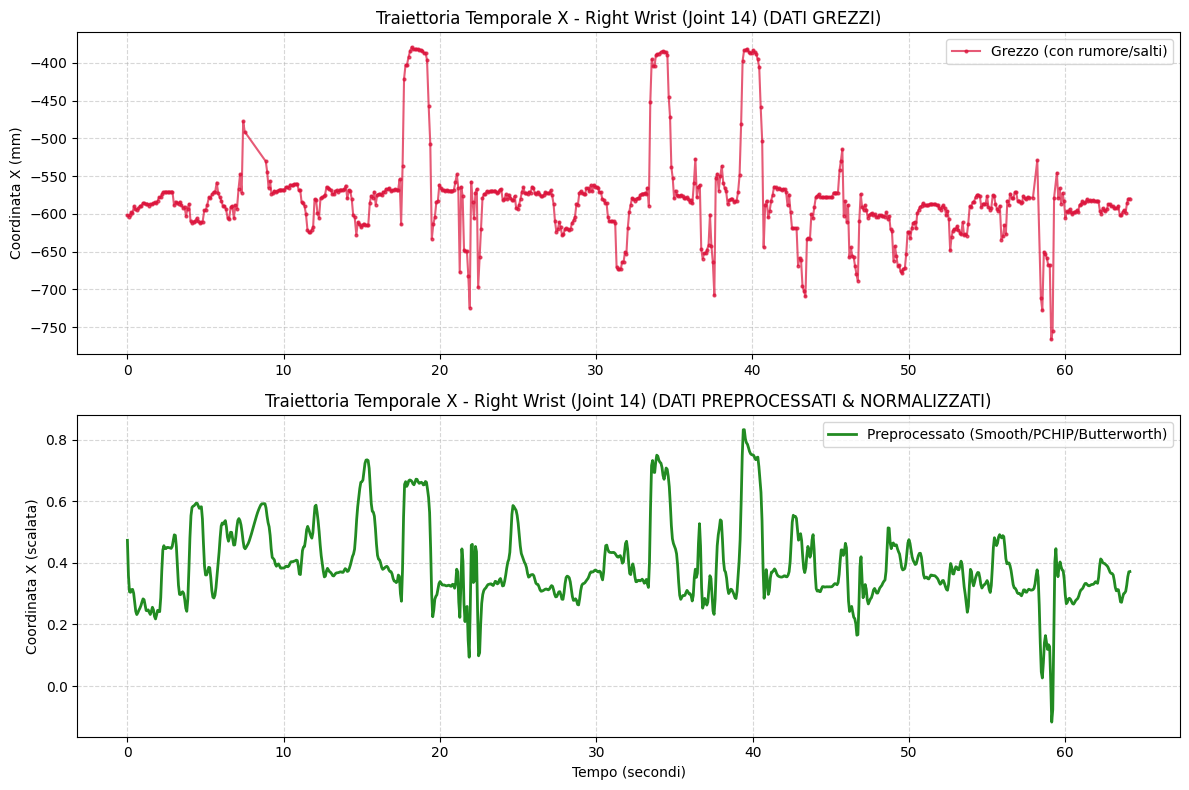

In [ ]:
import matplotlib.pyplot as plt

# 1. Recuperiamo il file grezzo e i dati preprocessati di test (Francesco - Video 1)
raw_path = experiment_data["Francesco"]["1"]["keypoints"]
preprocessed_data = processed_experiment_data["Francesco"]["1"]["preprocessed_keypoints"]

# Estraiamo i dati grezzi originali per il confronto
t_raw, coords_raw = parse_raw_keypoints_3d(raw_path)

# Consideriamo il polso destro (Joint 14 - Right Wrist) per l'analisi del movimento
JOINT_TO_PLOT = 14
joint_name = "Right Wrist (Joint 14)"

raw_joint_x = coords_raw[:, JOINT_TO_PLOT, 0]
prep_joint_x = preprocessed_data["positions"][:, JOINT_TO_PLOT, 0]
t_prep = preprocessed_data["timestamps"]

# === METRICHE QUANTITATIVE ===
# Calcoliamo il jitter (rumore ad alta frequenza) tramite la derivata seconda (accelerazione)
raw_acc = np.linalg.norm(np.diff(coords_raw[:, JOINT_TO_PLOT, :], n=2, axis=0), axis=1)
prep_acc = np.linalg.norm(np.diff(preprocessed_data["positions"][:, JOINT_TO_PLOT, :], n=2, axis=0), axis=1)

print("=== CONFRONTO METRICHE DI QUALITÀ ===")
print(f"Frequenza di campionamento:")
print(f"  - Grezza: Variabile (Media dt: {np.mean(np.diff(t_raw))*1000:.1f}ms)")
print(f"  - Preprocessata: Uniforme a 15 Hz (dt costante: {np.mean(np.diff(t_prep))*1000:.1f}ms)")
print(f"\nRumore di tracciamento (Mediana Accelerazione sul {joint_name}):")
print(f"  - Grezzo: {np.median(raw_acc):.2f} mm/frame²")
print(f"  - Preprocessato (Normalizzato): {np.median(prep_acc):.5f} unità/frame²")
print(f"  -> Riduzione drastica del jitter e dei movimenti teletrasportati!")

# === CONFRONTO GRAFICO ===
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Grafico 1: Traiettoria Grezza
axes[0].plot(t_raw - t_raw[0], raw_joint_x, label="Grezzo (con rumore/salti)", color="crimson", alpha=0.7, marker='o', markersize=2)
axes[0].set_title(f"Traiettoria Temporale X - {joint_name} (DATI GREZZI)")
axes[0].set_ylabel("Coordinata X (mm)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# Grafico 2: Traiettoria Preprocessata
axes[1].plot(t_prep - t_prep[0], prep_joint_x, label="Preprocessato (Smooth/PCHIP/Butterworth)", color="forestgreen", linewidth=2)
axes[1].set_title(f"Traiettoria Temporale X - {joint_name} (DATI PREPROCESSATI & NORMALIZZATI)")
axes[1].set_xlabel("Tempo (secondi)")
axes[1].set_ylabel("Coordinata X (scalata)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()